# 🌍 Phase 5 · Unsupervised Learning
## Lesson 0: Welcome, Setup, and the Big Idea

**Week 10 · Session 0 of 6 · ⏱ about 60 minutes**

---

Welcome! Take a breath. This is going to be fun.

For nine weeks you have been teaching computers by *showing them answers*: "this email is spam", "this house sold for 8 million shillings", "this farmer defaulted on a loan". The computer's job was to learn the pattern that connects **inputs** to those **answers**.

This week we do something that sounds almost impossible:

> **We hand the computer a pile of data with NO answers: and ask it to tell us what it notices.**

No teacher. No answer key. No labels. Just data, and curiosity.

By the end of this week you will be able to take a spreadsheet of customers, farmers, markets, or crops, and discover the **hidden groups, the hidden shape, and the hidden relationships** inside it. That is a genuine superpower. Analysts at banks, supermarkets, ministries of agriculture and farming cooperatives use exactly these tools every single day.

### 🎯 Learning objectives for this lesson
By the end you will be able to:
1. Explain the difference between **supervised** and **unsupervised** learning in your own words.
2. Name the **three families** of unsupervised learning and when to use each.
3. Verify that your **Python environment** is ready.
4. **Explore** every dataset we will use this week.
5. Run your **first clustering** in under 15 lines of code.

### 🧭 How this course works

| Icon | Meaning |
|---|---|
| 💡 | An intuition or analogy: read these slowly |
| 📐 | Some math, explained gently. Skip on a first read if you wish; come back later |
| ⚠️ | A common mistake. Learn from other people's pain |
| 🧩 | **Exercise**: you write code. Hints are hidden; open them *one at a time* |
| ✅ / ❌ / ⏳ | Self-check results: passed / try again / not attempted yet |
| 🎯 | Quiz: answer before peeking |

**Golden rule of learning to code:** *typing it yourself beats reading it.* When you see a code cell, don't just press Shift+Enter. Change a number. Break it. Fix it. That's how it sticks.

**It is completely normal to get errors.** Even professors get errors: every day. An error message is just the computer telling you what it needs. We will have a 🐞 *Debugging corner* whenever errors are likely.

## 1 · Supervised vs Unsupervised: the big picture

Imagine two ways of learning about fruit.

**Way 1: Supervised (with a teacher).** A teacher shows you 1,000 fruits, each labelled: *"mango", "banana", "avocado"*. After enough examples, you can look at a new fruit and name it. 
The labels are the **target** (we usually call it $y$) and the fruit's colour, size, and weight are the **features** (we call them $X$). You learn the rule $X \rightarrow y$.

**Way 2: Unsupervised (exploring on your own).** Nobody tells you the names. You are dropped into a market with a basket of 1,000 unknown fruits. You notice: *"these ones are yellow and curved… these ones are green, bumpy and heavy… these are small and red."* You sort them into piles on your own.
You've **discovered structure** without ever being told what to look for. There is no $y$. There is only $X$.

> 💡 **Intuition.** Supervised learning is *answering a question someone asked you*. Unsupervised learning is *noticing something nobody asked about*.

| | **Supervised** | **Unsupervised** |
|---|---|---|
| Data has labels $y$? | ✅ Yes | ❌ No |
| Goal | Predict $y$ for new data | Discover structure in $X$ |
| Typical question | *"Will this farmer repay the loan?"* | *"What kinds of farmers do we even have?"* |
| Examples (Weeks 6-9) | Regression, classification, trees | **This week:** clustering, PCA, association rules |
| How do you know it's "good"? | Compare predictions with true labels (accuracy, RMSE…) | …that's the hard part! Usefulness, stability, interpretability |

That last row is the **central challenge of this entire week**. When there is no answer key, who grades your work? We will return to this question again and again. Keep it in the back of your mind.

## 2 · The three families of unsupervised learning

```
                        UNSUPERVISED LEARNING
                                 │
        ┌────────────────────────┼─────────────────────────┐
        ▼                        ▼                         ▼
   1. CLUSTERING        2. DIMENSIONALITY          3. ASSOCIATION RULES
   "Which rows are         REDUCTION                "Which items go
    similar?"             "Which columns            together?"
                           matter / can I
                           compress?"
   • K-Means              • PCA                     • Support
   • Hierarchical         • Feature extraction      • Confidence
   • DBSCAN               • Visualisation           • Lift · Apriori
```

| Family | Works on | Output | Real-world example |
|---|---|---|---|
| **Clustering** | Rows (customers, farmers, markets) | A group number for each row | Segment 800 customers into 5 personas for targeted offers |
| **Dimensionality reduction** | Columns (features) | Fewer, new columns that keep most of the information | Compress 14 farm measurements into 2 numbers you can plot |
| **Association rules** | Transactions (baskets of items) | If-then rules like *{DAP fertilizer} ⇒ {hybrid maize seed}* | Decide which agro-dealer products to shelve together |

> 🌾 **Agricultural lens.** Agriculture is *full* of unlabeled data: thousands of farmers nobody has categorised, hundreds of markets with different personalities, dozens of crops that behave similarly in price. Extension officers, cooperatives, and policymakers constantly need to *"group like with like"* to design the right support for each group. One-size-fits-all advice fails; unsupervised learning is how you find the right sizes.

## 3 · Setup: is your computer ready?

Let's make sure everything works. Run the next cell (click it, then press **Shift + Enter**).

You need Python 3.9+ and these libraries: `numpy`, `pandas`, `matplotlib`, `scikit-learn`, `scipy`, `seaborn`, `mlxtend`. 
If anything is missing, install everything at once from your terminal:

```bash
pip install -r requirements.txt
```

In [1]:
import sys, platform
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn, scipy

print("Python      :", sys.version.split()[0])
print("numpy       :", np.__version__)
print("pandas      :", pd.__version__)
print("matplotlib  :", matplotlib.__version__)
print("scikit-learn:", sklearn.__version__)
print("scipy       :", scipy.__version__)

try:
    import mlxtend
    print("mlxtend     :", mlxtend.__version__)
except ImportError:
    print("mlxtend     : NOT INSTALLED  ->  run:  pip install mlxtend   (needed in Lesson 5)")

Python      : 3.12.3
numpy       : 2.5.4
pandas      : 3.0.6
matplotlib  : 3.11.2
scikit-learn: 1.9.1
scipy       : 1.18.1
mlxtend     : 0.25.0


> 🐞 **Debugging corner.** `ModuleNotFoundError: No module named 'sklearn'`? The package is installed under the name **scikit-learn** but imported as **sklearn**. Run `pip install scikit-learn`, then **restart the kernel** (Kernel → Restart) and run the cell again.

Now we import our course helper module (`course_utils.py`, sitting next to this notebook) and switch on nice plot styling.

In [2]:
from course_utils import set_style, load, check
set_style()

# A good habit: make results reproducible. Anything "random" will now give the same answer every run.
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
print("Ready to learn! 🚀")

Ready to learn! 🚀


## 4 · Meet your datasets 🗂️

All datasets live in the `data/` folder. **They are synthetic** (generated by a script, so you can regenerate them any time) but modelled on real Kenyan retail and agricultural patterns. We built hidden structure into them, just like real life has hidden structure, and later we'll check whether your algorithms found it.

| File | Rows | What one row is | Used in |
|---|---:|---|---|
| `retail_customers.csv` | 800 | a shopper at a supermarket chain | Lessons 1, 2, 6 · **Project 1** |
| `farmers.csv` | 700 | a farming household | Lessons 1, 4, 6 · **Project 2** |
| `markets.csv` | 103 | an agricultural market | Lessons 1, 3 · **Project 3** |
| `products.csv` | 48 | an agricultural commodity | Lessons 2, 4 · **Project 4** |
| `grocery_baskets.csv` | 2,500 baskets | one grocery purchase (long format) | Lesson 5 |
| `agro_input_baskets.csv` | 3,000 baskets | one agro-dealer purchase | Lesson 5 · Capstone |
| `*_truth.csv` | | the **hidden answers** | 🔒 *Only peek when told to!* |

> ⚠️ **The truth files are the "answer key".** In real projects, they don't exist. Treat them like the back of the textbook: don't look until you've committed to your own answer.

Let's load the farmers and take a first look. This is what every data scientist does first, always: **look at the data before you model it**.

In [3]:
farmers = load("farmers")
print("Shape:", farmers.shape, "  (rows, columns)")
farmers.head()

Shape: (700, 15)   (rows, columns)


,farmer_id,county,primary_crop,farm_size_acres,yield_bags_per_acre,fertilizer_kg_per_acre,irrigated,labour_days_per_acre,improved_seed,coop_member,distance_to_market_km,post_harvest_loss_pct,experience_years,extension_visits_per_year,annual_revenue_kes
0,F0280,Trans Nzoia,Maize,29.79,36.2,72.4,0,4.2,1,0,4.1,8.4,1,0,2939400
1,F0591,Nakuru,Potatoes,7.83,22.0,27.6,0,23.0,0,1,5.1,9.2,1,2,501200
2,F0446,Nyeri,French Beans,3.48,38.4,32.0,1,88.9,1,1,9.3,6.6,10,3,414100
3,F0084,Narok,Beans,1.26,10.1,19.4,0,34.3,0,0,10.5,26.9,10,2,32000
4,F0460,Machakos,Onions,1.78,34.7,114.2,1,47.9,1,0,8.7,25.6,1,3,141600


In [4]:
# What kinds of columns do we have? Any missing values?
farmers.info()

<class 'pandas.DataFrame'>
RangeIndex: 700 entries, 0 to 699
Data columns (total 15 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   farmer_id                  700 non-null    str    
 1   county                     700 non-null    str    
 2   primary_crop               700 non-null    str    
 3   farm_size_acres            700 non-null    float64
 4   yield_bags_per_acre        700 non-null    float64
 5   fertilizer_kg_per_acre     685 non-null    float64
 6   irrigated                  700 non-null    int64  
 7   labour_days_per_acre       700 non-null    float64
 8   improved_seed              700 non-null    int64  
 9   coop_member                700 non-null    int64  
 10  distance_to_market_km      694 non-null    float64
 11  post_harvest_loss_pct      690 non-null    float64
 12  experience_years           700 non-null    int64  
 13  extension_visits_per_year  700 non-null    int64  
 14  annua

In [5]:
# Quick statistical summary of the numeric columns
farmers.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
farm_size_acres,700.0,11.49,34.43,0.8,1.84,3.64,7.40,757.6
yield_bags_per_acre,700.0,21.56,10.71,6.4,12.20,19.65,27.50,56.8
fertilizer_kg_per_acre,685.0,46.19,36.26,0.0,14.60,39.30,66.90,181.6
irrigated,700.0,0.24,0.42,0.0,0.00,0.00,0.00,1.0
labour_days_per_acre,700.0,32.67,19.67,2.0,18.60,31.55,43.90,98.5
improved_seed,700.0,0.62,0.49,0.0,0.00,1.00,1.00,1.0
coop_member,700.0,0.44,0.50,0.0,0.00,0.00,1.00,1.0
distance_to_market_km,694.0,9.30,6.00,1.0,5.20,7.60,12.10,39.5
post_harvest_loss_pct,690.0,17.12,9.34,1.0,9.43,15.50,25.78,37.4
experience_years,700.0,13.12,7.43,1.0,8.00,13.00,18.00,40.0


**Things a good analyst notices (pause and see if you spotted them):**

- `farm_size_acres` has a maximum far above the 75th percentile. A few **huge** farms (or typos) will stretch the scale. We'll learn that this matters a *lot* for distance-based algorithms.
- Some columns have **missing values** (`fertilizer_kg_per_acre`, `post_harvest_loss_pct`, `distance_to_market_km`). Most algorithms can't handle `NaN`.
- Columns are on **wildly different scales**: revenue is in millions, `irrigated` is 0 or 1. Remember this: it's the #1 cause of bad clustering.

## 5 · Your first clustering: in 15 lines ✨

Before we study *how* clustering works, let's just **see it work**. We'll take 800 supermarket customers and let an algorithm called **K-Means** split them into groups using two numbers: *how often they shop* and *how much they spend per visit*.

You'll understand every line of this properly in Lesson 1. For now, just enjoy the moment.

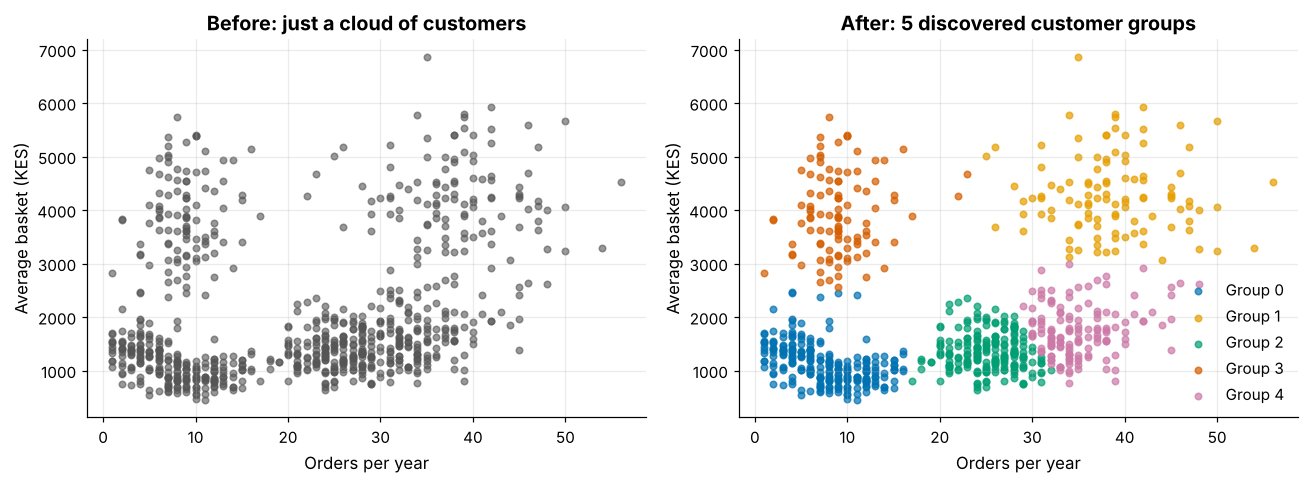

In [6]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

customers = load("retail_customers")
X = customers[["orders_per_year", "avg_basket_kes"]]

# Put both columns on a comparable scale (we'll explain why in Lesson 1)
X_scaled = StandardScaler().fit_transform(X)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# LEFT: what the computer sees. Just points. No labels.
axes[0].scatter(X["orders_per_year"], X["avg_basket_kes"], s=18, alpha=0.6, color="#555")
axes[0].set_title("Before: just a cloud of customers")

# RIGHT: ask K-Means to find 5 groups
labels = KMeans(n_clusters=5, n_init=10, random_state=RANDOM_STATE).fit_predict(X_scaled)
for g in range(5):
    pts = X[labels == g]
    axes[1].scatter(pts["orders_per_year"], pts["avg_basket_kes"], s=18, alpha=0.7, label=f"Group {g}")
axes[1].set_title("After: 5 discovered customer groups")
axes[1].legend()

for ax in axes:
    ax.set_xlabel("Orders per year")
    ax.set_ylabel("Average basket (KES)")
plt.tight_layout()
plt.show()

**Look at that.** Nobody told the algorithm *"there are loyal big spenders and bargain hunters"*. It discovered those patterns from the numbers alone.

> 🤔 **Honesty moment.** Did you notice the `StandardScaler` line? It put "orders per year" (tens) and "basket size" (thousands) on a comparable scale before clustering. Without it, basket size would completely drown out orders-per-year in the distance calculation, and the groups would turn into horizontal stripes. That's the **scaling problem**: one of the most important ideas this week, and it gets a proper treatment in Lesson 1. Go try it: change `fit_predict(X_scaled)` to `fit_predict(X)` and see what happens!

## 6 · 🧩 Practice time

Now it's your turn. These first exercises are gentle warm-ups.

### 🧩 Exercise 1: Explore the farmers dataset
**Difficulty:** ⭐  |  **Time:** ~5 min

Using the `farmers` DataFrame we loaded above, create these variables:

- `n_rows`: the number of farmers (rows)
- `n_missing`: the **total** number of missing cells in the whole DataFrame
- `biggest_county`: the name of the county that has the **most** farmers
- `median_farm_size`: the median of `farm_size_acres`

<details><summary>💡 Hint 1</summary>

`len(df)` or `df.shape[0]` gives the number of rows.

</details>
<details><summary>💡 Hint 2</summary>

`df.isna()` gives True/False for each cell. `True` counts as 1 when you `.sum()`. You'll need to sum **twice** (once per column, then across columns): or use `.sum().sum()`.

</details>
<details><summary>💡 Hint 3</summary>

`df['county'].value_counts()` sorts counties from most to least common. `.idxmax()` on it returns the name of the biggest one.

</details>

In [7]:
# YOUR CODE HERE
# n_rows = ...
# n_missing = ...
# biggest_county = ...
# median_farm_size = ...

In [ ]:
# ✔ Self-check (run me after you've written your answer)
check('n_rows is 700', lambda: n_rows == 700)
check('n_missing is 31', lambda: n_missing == 31)
check('biggest_county is a string in the data', lambda: biggest_county in set(farmers['county']))
check('median_farm_size is about 3.6 acres', lambda: 3.0 < median_farm_size < 4.2)

### 🧩 Exercise 2: Supervised or unsupervised?
**Difficulty:** ⭐  |  **Time:** ~5 min

For each scenario, decide whether it is a **S**upervised or **U**nsupervised problem. Fill in the dictionary `answers` with `"S"` or `"U"` for each number.

1. Predict next month's maize price from past prices and rainfall.
2. Group 2,000 smallholders into types so the cooperative can design different training programmes.
3. Decide whether a loan application is *approved* or *rejected*, given 10,000 past applications with their outcomes.
4. Find which products are frequently bought together at an agro-dealer.
5. Squash 40 soil-test measurements into 3 summary numbers for easier plotting.
6. Identify which photos of maize leaves show disease, using 5,000 photos labelled *healthy* / *diseased*.
7. Discover that some markets behave oddly and don't fit any usual pattern (without a list of "odd" markets).

<details><summary>💡 Hint 1</summary>

Ask one question: *Do I already have a column of correct answers (labels) that I want the model to predict?* Yes → supervised. No → unsupervised.

</details>
<details><summary>💡 Hint 2</summary>

Careful with #7: no one has provided a list of 'odd' markets, so there is nothing to predict. That's unsupervised (specifically, noise / outlier discovery).

</details>

In [9]:
answers = {
    1: "?",
    2: "?",
    3: "?",
    4: "?",
    5: "?",
    6: "?",
    7: "?",
}

In [ ]:
# ✔ Self-check (run me after you've written your answer)
check('1 is supervised (regression)', lambda: answers[1] == 'S')
check('2 is unsupervised (clustering)', lambda: answers[2] == 'U')
check('3 is supervised (classification)', lambda: answers[3] == 'S')
check('4 is unsupervised (association rules)', lambda: answers[4] == 'U')
check('5 is unsupervised (dimensionality reduction)', lambda: answers[5] == 'U')
check('6 is supervised (image classification)', lambda: answers[6] == 'S')
check('7 is unsupervised (outlier/noise discovery)', lambda: answers[7] == 'U')

### 🧩 Exercise 3: Your very first clustering
**Difficulty:** ⭐⭐  |  **Time:** ~8 min

Cluster the **markets** into **3** groups using just two features: `avg_daily_traders` and `distance_to_city_km`.

1. Load the data: `markets = load("markets")`
2. Build `Xm` = the two columns as a DataFrame.
3. Because the two columns have different scales, **standardise** them first with `StandardScaler` (`fit_transform`).
4. Fit `KMeans(n_clusters=3, n_init=10, random_state=42)` and store the group numbers in `market_labels`.
5. Store the number of markets in each group in `sizes` (a list, sorted from smallest to largest).

<details><summary>💡 Hint 1</summary>

```python
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
Xm_scaled = scaler.fit_transform(Xm)
```

</details>
<details><summary>💡 Hint 2</summary>

`KMeans(...).fit_predict(Xm_scaled)` fits the model and returns an array with one group number per market.

</details>
<details><summary>💡 Hint 3</summary>

`np.bincount(market_labels)` counts how many items carry each label 0, 1, 2. Wrap it in `sorted(...)` and `.tolist()`.

</details>

In [11]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# YOUR CODE HERE

In [ ]:
# ✔ Self-check (run me after you've written your answer)
check('there is one label per market (103)', lambda: len(market_labels) == 103)
check('exactly 3 different groups', lambda: len(set(market_labels)) == 3)
check('sizes sum to 103', lambda: sum(sizes) == 103)
check('sizes sorted ascending', lambda: sizes == sorted(sizes))

### 🎯 Check your understanding
*Try to answer each question out loud or on paper before you peek.*

**Q1.** In one sentence: what is the *main* difference between supervised and unsupervised learning?

<details><summary>Show answer</summary>

Supervised learning uses **labelled** data (known answers) to learn to predict those answers. Unsupervised learning has **no labels** and instead discovers structure (groups, simplifications, or relationships) inside the data itself.

</details>

**Q2.** Name the three families of unsupervised learning covered this week, and one question each answers.

<details><summary>Show answer</summary>

**Clustering** → *which rows are similar?* · **Dimensionality reduction** → *which columns matter, or can I compress them?* · **Association rule learning** → *which items occur together?*

</details>

**Q3.** A colleague says: *"My clustering model has 94% accuracy!"* Why should you raise an eyebrow?

<details><summary>Show answer</summary>

Accuracy requires **true labels** to compare against. In real unsupervised problems there are none, so accuracy isn't defined. Either they secretly had labels (then why not do supervised learning?), or the number is meaningless. We evaluate clusters with *internal* measures (silhouette etc.), stability, and (most importantly) **usefulness**.

</details>

**Q4.** Why do we scale features before running a distance-based algorithm?

<details><summary>Show answer</summary>

Distances add up differences across columns. A column measured in thousands (e.g. revenue in KES) would completely dominate a column measured in 0–1 (e.g. `irrigated`). Scaling puts all columns on a comparable footing so each gets a fair vote.

</details>

## 7 · What's next: your week at a glance

| Session | Topic | You will be able to… |
|---|---|---|
| **0** | Welcome *(you are here)* | Set up, explore data, run a first clustering |
| **1** | **K-Means** | Build K-Means from scratch; choose *k*; interpret clusters |
| **2** | **Hierarchical clustering** | Read a dendrogram; choose a linkage |
| **3** | **DBSCAN** | Find arbitrary-shaped clusters and spot noise |
| **4** | **PCA & dimensionality reduction** | Compress data; visualise 14 dimensions in 2 |
| **5** | **Association rules** | Mine support, confidence, lift with Apriori |
| **6** | **Evaluating & profiling clusters** | Judge clusterings with no labels; tell the story |
| **P1–P4** | **Four practical projects** | Customers · Farmers · Markets · Products |
| **Capstone** | **Agricultural Intelligence Brief** | Combine everything in one professional report |

### 📚 Before the next lesson
- Re-run this notebook top to bottom (**Kernel → Restart & Run All**) and make sure no cell errors.
- Try changing `n_clusters=5` to `3` and `8` in the first-taste cell. What do you notice?

> 🧠 **Remember.** Unsupervised learning has no right answer to compare against. Our job is to find structure that is **real, stable, and useful**: and to explain it clearly to a human being.

See you in Lesson 1. 👋